# Sequential models: from AR to ARX to recurrent models

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/sequential-models/02-silverbox-arx-rnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

The [Silverbox benchmark](https://www.nonlinearbenchmark.org/benchmarks/silverbox) records the response of an electronic system designed to behave like a Duffing oscillator. It provides one deliberately applied input, `V1`, and one measured response, `V2`. A useful mechanical analogy is a force-like excitation $u_t$ and a displacement-like response $y_t$.

The samples are synchronized. In the discrete-time models below, the response at time $t$ may depend on the imposed input $u_t$, earlier input values, and the system's earlier responses. This expresses a physically plausible causal direction—input to response—without assuming that every effect is instantaneous.

We will predict the next response using information available at that time. The comparison moves from models that only see the response history to models that can also use the known applied input, with linear and nonlinear recurrent representations along the way.

## What you will do

1. Load one real input--response system-identification benchmark.
2. Preserve its chronological training/test experiment split.
3. Fit an AR(20) model using only past response values.
4. Add the known forcing signal to create an ARX(20) model.
5. Fit a response-only RNN: the nonlinear recurrent counterpart to AR.
6. Give the RNN the known forcing signal, making it the nonlinear recurrent counterpart to ARX.
7. Compare all models using a recursive multi-step held-out forecast.
8. *(Optional)* Swap the input-aware RNN cell for an LSTM while keeping the warmup and scoring protocol fixed.

## 1. Load the measured input--response experiments

The `nonlinear-benchmarks` package downloads the official Silverbox record to the notebook runtime. Nothing is fitted to the held-out experiment.

In [1]:
# This package downloads the official Silverbox benchmark when it is first used.
try:
    from nonlinear_benchmarks import Silverbox
except ModuleNotFoundError:
    %pip install -q nonlinear-benchmarks
    from nonlinear_benchmarks import Silverbox

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Prefer an NVIDIA GPU (CUDA), then an Apple Silicon GPU (MPS), then the CPU.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"PyTorch device: {device}")

PyTorch device: mps


In [2]:
# Store the official download in the notebook's local working directory.
# In Colab, this directory is temporary and disappears when the runtime ends.
benchmark_directory = Path("silverbox-data")
benchmark_directory.mkdir(exist_ok=True)
training_record, test_records = Silverbox(dir_placement=benchmark_directory)
test_record = test_records[0]  # The official held-out multisine experiment.

u_train = np.asarray(training_record.u, dtype=float).reshape(-1)
y_train = np.asarray(training_record.y, dtype=float).reshape(-1)
u_test = np.asarray(test_record.u, dtype=float).reshape(-1)
y_test = np.asarray(test_record.y, dtype=float).reshape(-1)
sampling_time = float(training_record.sampling_time)

print(f"Training samples: {len(y_train):,}")
print(f"Held-out samples: {len(y_test):,}")
print(f"Sampling interval: {sampling_time * 1_000:.4f} ms")

dataset not found downloading from https://drive.google.com/file/d/17iS-6oBUUgrmiAcrZoG9S5sOaljZnDSy/view 
 in silverbox-data/Silverbox/SilverboxFiles.zip


extracting file...
save_loc='silverbox-data/Silverbox/SilverboxFiles.zip'
Training samples: 65,062
Held-out samples: 21,688
Sampling interval: 1.6384 ms


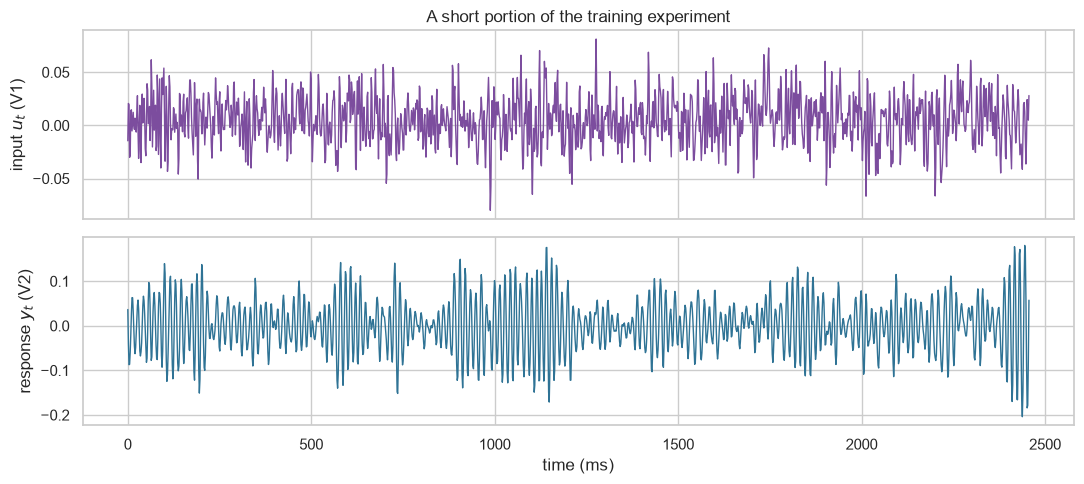

In [3]:
display_samples = 1_500
time_ms = np.arange(display_samples) * sampling_time * 1_000

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(time_ms, u_train[:display_samples], color="#7c4d9e", linewidth=1)
axes[0].set(ylabel="input $u_t$ (V1)", title="A short portion of the training experiment")
axes[1].plot(time_ms, y_train[:display_samples], color="#2f7395", linewidth=1)
axes[1].set(xlabel="time (ms)", ylabel="response $y_t$ (V2)")
plt.tight_layout()
plt.show()

## 2. Set up one forecasting protocol

An **autoregressive (AR)** model forecasts a response from its own past values. An **autoregressive model with exogenous input (ARX)** extends that idea by adding one or more external signals that are available at prediction time. Such an input might be a commanded actuator signal, an ambient measurement, or a known operating schedule; it is *exogenous* because it is supplied from outside the response's own history.

Here, `V1` is the exogenous input and `V2` is the response. We will first apply AR to forecast `V2` purely from its past values. Next, we add the known applied input `V1` to form ARX. We then build two recurrent models: first a response-only RNN, and then an RNN that also receives the known input.

There are two useful forecasting protocols:

- **One-step-ahead forecasting (observed lags):** use the actual preceding `V2` measurements at every time step.
- **Recursive multi-step forecasting (predicted lags):** after an initial window, reuse each prediction as a lagged `V2` input for later predictions.

We use recursive multi-step forecasting throughout this notebook. Every model uses the first $p=20$ measured responses in the held-out experiment only to initialize its lag history or recurrent state. Afterwards, later true `V2` responses are **not** fed back to the model.

The applied input $u_t$ remains known throughout the held-out experiment. That is natural in system identification: it is an externally imposed forcing signal, not an unknown future response measurement.

For this example, the two linear models are

$$
egin{aligned}
	ext{AR}(p):\quad \widehat{y}_t &= eta_0 + \sum_{j=1}^{p}eta_j y_{t-j},\
	ext{ARX}(p):\quad \widehat{y}_t &= eta_0 + \sum_{j=1}^{p}eta_j y_{t-j} + \sum_{j=0}^{p}\gamma_j u_{t-j}.
\end{aligned}
$$

In [4]:
ORDER = 20


def make_linear_design(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[np.ndarray, np.ndarray]:
    """Build one-step input rows for an AR or ARX model.

    Args:
        input_signal: Known forcing values $u_t$ from one experiment.
        output_signal: Measured response values $y_t$ from one experiment.
        order: Number of earlier response values to include.
        include_input: Whether to append the current and lagged input values.

    Returns:
        A feature matrix and matching next-response target vector.
    """
    rows: list[np.ndarray] = []
    targets: list[float] = []
    for index in range(order, len(output_signal)):
        response_lags = output_signal[index - order : index][::-1]
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            rows.append(np.concatenate((response_lags, input_lags)))
        else:
            rows.append(response_lags)
        targets.append(output_signal[index])
    return np.asarray(rows), np.asarray(targets)


def fit_linear_forecaster(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[StandardScaler, LinearRegression]:
    """Fit a linear AR or ARX forecaster.

    Args:
        input_signal: Known forcing values from the training experiment.
        output_signal: Measured training responses.
        order: Number of earlier response values to use.
        include_input: Whether to fit an ARX model instead of an AR model.

    Returns:
        The training-only feature scaler and fitted linear model.
    """
    features, targets = make_linear_design(
        input_signal=input_signal,
        output_signal=output_signal,
        order=order,
        include_input=include_input,
    )
    # Fit the scaler on training rows only, then fit ordinary least squares.
    scaler = StandardScaler().fit(features)
    model = LinearRegression().fit(scaler.transform(features), targets)
    return scaler, model


def recursive_linear_forecast(
    *,
    input_signal: np.ndarray,
    observed_output: np.ndarray,
    order: int,
    include_input: bool,
    scaler: StandardScaler,
    model: LinearRegression,
) -> np.ndarray:
    """Make a recursive multi-step forecast after an initial response window.

    Args:
        input_signal: Known input values for the held-out experiment.
        observed_output: Held-out responses; only the first `order` values initialize history.
        order: Number of prior responses in every forecast feature row.
        include_input: Whether to use the known input values (ARX).
        scaler: Feature scaler fitted using training rows only.
        model: Fitted AR or ARX linear model.

    Returns:
        Predictions with `np.nan` during the initialization window.
    """
    history = list(observed_output[:order])
    predictions = np.full(len(observed_output), np.nan)
    for index in range(order, len(observed_output)):
        response_lags = np.asarray(history[-order:][::-1])
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            feature_row = np.concatenate((response_lags, input_lags))
        else:
            feature_row = response_lags
        prediction = model.predict(scaler.transform(feature_row.reshape(1, -1)))[0]
        history.append(float(prediction))  # Later lags are predictions, not labels.
        predictions[index] = prediction
    return predictions


def rmse(*, actual: np.ndarray, predicted: np.ndarray, warmup: int) -> float:
    """Calculate root-mean-square error after the initialization window.

    Args:
        actual: Observed held-out response values.
        predicted: Recursive forecasts aligned with `actual`.
        warmup: Number of initial values excluded from scoring.

    Returns:
        The held-out recursive multi-step RMSE.
    """
    return float(np.sqrt(np.mean((actual[warmup:] - predicted[warmup:]) ** 2)))

## 3. Start with a response-only AR(20) model

The AR model has 20 lagged `V2` values but no access to `V1`. During the recursive multi-step held-out forecast, it must infer future responses solely from its own earlier response forecasts.

In [5]:
ar_scaler, ar_model = fit_linear_forecaster(
    input_signal=u_train,
    output_signal=y_train,
    order=ORDER,
    include_input=False,
)
ar_prediction = recursive_linear_forecast(
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    include_input=False,
    scaler=ar_scaler,
    model=ar_model,
)
ar_rmse = rmse(actual=y_test, predicted=ar_prediction, warmup=ORDER)
print(f"AR({ORDER}) recursive multi-step held-out RMSE: {ar_rmse:.5f}")

AR(20) recursive multi-step held-out RMSE: 0.05429


## 4. Add the causal forcing signal: ARX(20)

In this Silverbox system, `V1` is the ARX model's exogenous input. The model receives the same response history plus the current and 20 previous `V1` values. Because `V1` is deliberately imposed on the physical system, it is reasonable to treat it as known at prediction time. This is different from leaking later `V2` labels into the model.

ARX(20) recursive multi-step held-out RMSE: 0.00694


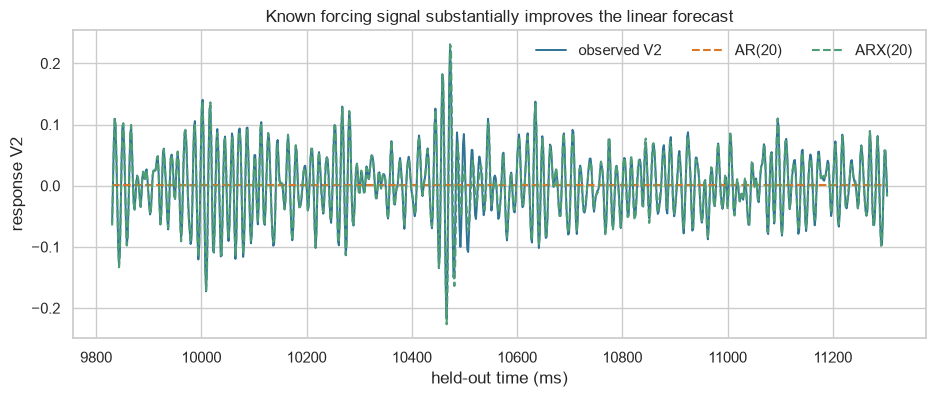

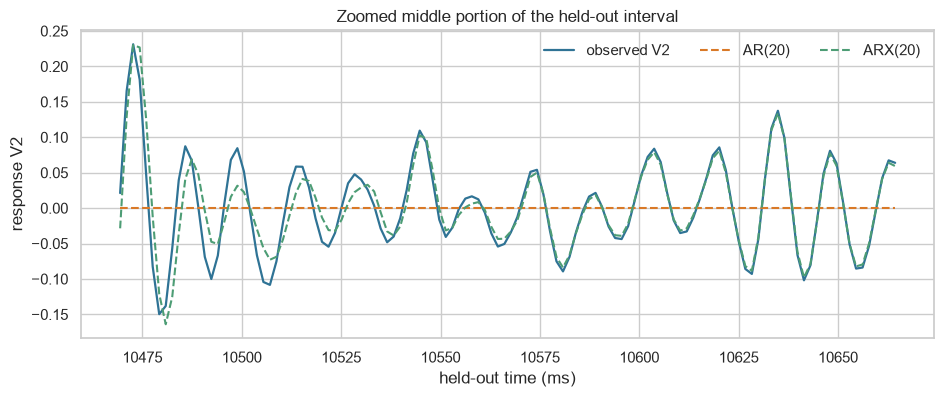

In [6]:
arx_scaler, arx_model = fit_linear_forecaster(
    input_signal=u_train,
    output_signal=y_train,
    order=ORDER,
    include_input=True,
)
arx_prediction = recursive_linear_forecast(
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    include_input=True,
    scaler=arx_scaler,
    model=arx_model,
)
arx_rmse = rmse(actual=y_test, predicted=arx_prediction, warmup=ORDER)
print(f"ARX({ORDER}) recursive multi-step held-out RMSE: {arx_rmse:.5f}")

window_start = 6_000
window_length = 900
window = slice(window_start, window_start + window_length)
window_time = np.arange(window_start, window_start + window_length) * sampling_time * 1_000

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(window_time, y_test[window], color="#2f7395", linewidth=1.4, label="observed V2")
ax.plot(window_time, ar_prediction[window], color="#d97927", linestyle="--", label="AR(20)")
ax.plot(window_time, arx_prediction[window], color="#4d9d75", linestyle="--", label="ARX(20)")
ax.set(xlabel="held-out time (ms)", ylabel="response V2", title="Known forcing signal substantially improves the linear forecast")
ax.legend(frameon=False, ncol=3)
plt.show()

# Inspect the middle of the displayed interval on a tighter time scale.
zoom_window_start = window_start + window_length // 2 - 60
zoom_window_length = 120
zoom_window = slice(zoom_window_start, zoom_window_start + zoom_window_length)
zoom_time = np.arange(zoom_window_start, zoom_window_start + zoom_window_length) * sampling_time * 1_000

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(zoom_time, y_test[zoom_window], color="#2f7395", linewidth=1.6, label="observed V2")
ax.plot(zoom_time, ar_prediction[zoom_window], color="#d97927", linestyle="--", label="AR(20)")
ax.plot(zoom_time, arx_prediction[zoom_window], color="#4d9d75", linestyle="--", label="ARX(20)")
ax.set(
    xlabel="held-out time (ms)",
    ylabel="response V2",
    title="Zoomed middle portion of the held-out interval",
)
ax.legend(frameon=False, ncol=3)
plt.show()

## 5. Learn a nonlinear state from the response alone

A **recurrent neural network (RNN)** extends the MLP idea to sequential data. An MLP applies a learned transformation once to one fixed input vector. An RNN instead applies the **same small learned transformation** repeatedly as it moves through a sequence.

This first RNN is response-only: at time $t$, it receives $y_{t-1}$ and its previous hidden state $\mathbf{h}_{t-1}$, but it does **not** see `V1`. It therefore has the same type of observed response information as AR. The difference is how it represents history: AR retains 20 explicit lags and combines them linearly, whereas the RNN compresses earlier information into a learned nonlinear state.

$$
\mathbf{h}_t = 	anh(W_h \mathbf{h}_{t-1} + W_y y_{t-1} + b_h),
\qquad \widehat{y}_t = f(\mathbf{h}_t).
$$

The hidden state is a learned vector of internal memory: it is not a measured physical state, but it can summarize useful information from earlier positions in the sequence. We use $	anh$ as its activation because it is smooth, keeps each hidden-state value between $-1$ and $1$, and preserves positive and negative values.

For the held-out recursive forecast, the first 20 observed responses **prime** the hidden state. The model then advances one time step at a time, using its prior **predicted** response to obtain both the next prediction and the next hidden state. During training, it uses the observed prior response—called *teacher forcing*—and carries its state forward through the training record. We detach the state every 256 positions, so gradients travel through one chunk rather than the entire record; this is truncated backpropagation through time.

In [7]:
class RecurrentPredictor(torch.nn.Module):
    """Process a sequence while carrying a recurrent state.

    Args:
        input_size: Number of values supplied at each time step.
        hidden_size: Number of values carried by the learned recurrent state.
    """

    def __init__(self, *, input_size: int, hidden_size: int) -> None:
        super().__init__()
        self.rnn = torch.nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True,
            nonlinearity="tanh",
        )
        self.readout = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, hidden_size),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_size, 1),
        )

    def forward(
        self,
        sequence: torch.Tensor,
        hidden_state: torch.Tensor | None = None,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Predict standardized responses and return the state for the next step.

        Args:
            sequence: Tensor of shape `(batch, time, input_size)`.
            hidden_state: State from the preceding sequence, or `None` to start at zero.

        Returns:
            Standardized predictions with shape `(batch, time)` and the next hidden state.
        """
        hidden_values, next_hidden_state = self.rnn(sequence, hidden_state)
        predictions = self.readout(hidden_values).squeeze(-1)
        return predictions, next_hidden_state


def make_teacher_forced_sequence(
    *,
    input_signal: np.ndarray | None,
    output_signal: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """Create chronological RNN inputs and next-response targets.

    Args:
        input_signal: Standardized known forcing signal, or `None` for a response-only RNN.
        output_signal: Standardized response signal.

    Returns:
        Inputs containing either `[y_(t-1)]` or `[u_t, y_(t-1)]`, plus targets `y_t`.
    """
    if input_signal is None:
        inputs = output_signal[:-1, None]
    else:
        inputs = np.column_stack((input_signal[1:], output_signal[:-1]))
    targets = output_signal[1:]
    return inputs.astype(np.float32), targets.astype(np.float32)


def detach_recurrent_state(
    hidden_state: torch.Tensor | tuple[torch.Tensor, torch.Tensor],
) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
    """Keep state values but remove their old gradient history."""
    if isinstance(hidden_state, tuple):
        return tuple(value.detach() for value in hidden_state)
    return hidden_state.detach()


def train_stateful_sequence_model(
    *,
    model: torch.nn.Module,
    inputs: np.ndarray,
    targets: np.ndarray,
    epochs: int,
    chunk_size: int,
) -> list[float]:
    """Train an RNN or LSTM chronologically with truncated backpropagation.

    Args:
        model: Sequence model whose output is one standardized response per time step.
        inputs: Chronological tensor with shape `(time, features)`.
        targets: Standardized next-response targets with shape `(time,)`.
        epochs: Number of passes through the chronological training record.
        chunk_size: Number of time steps through which gradients are propagated.

    Returns:
        The mean chunk MSE after each epoch.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003, weight_decay=1e-5)
    loss_function = torch.nn.MSELoss()
    training_losses: list[float] = []

    for _ in range(epochs):
        model.train()
        chunk_losses: list[float] = []
        hidden_state = None
        for start in range(0, len(inputs), chunk_size):
            stop = min(start + chunk_size, len(inputs))
            sequence_chunk = torch.from_numpy(inputs[start:stop][None, ...]).to(device)
            target_chunk = torch.from_numpy(targets[start:stop][None, ...]).to(device)
            optimizer.zero_grad()  # PyTorch otherwise accumulates gradients from earlier chunks.
            prediction_chunk, hidden_state = model(sequence_chunk, hidden_state)
            loss = loss_function(prediction_chunk, target_chunk)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            # Carry the numerical state onward, but stop gradients at this boundary.
            hidden_state = detach_recurrent_state(hidden_state)
            chunk_losses.append(loss.item())
        training_losses.append(float(np.mean(chunk_losses)))

    return training_losses


def recursive_stateful_forecast(
    *,
    model: torch.nn.Module,
    input_signal: np.ndarray | None,
    observed_output: np.ndarray,
    warmup: int,
    input_mean: float | None,
    input_std: float | None,
    output_mean: float,
    output_std: float,
) -> np.ndarray:
    """Make a state-carrying recursive forecast.

    Args:
        model: Trained RNN or LSTM that predicts standardized responses.
        input_signal: Known held-out forcing signal, or `None` for response-only recurrence.
        observed_output: Held-out response; only the first `warmup` values prime state.
        warmup: Number of observed held-out values used before recursive prediction.
        input_mean: Training-input mean when `input_signal` is supplied.
        input_std: Training-input standard deviation when `input_signal` is supplied.
        output_mean: Training-output mean.
        output_std: Training-output standard deviation.

    Returns:
        Recursive predictions aligned with the held-out response.
    """
    predictions = np.full(len(observed_output), np.nan)

    def step_input(*, index: int, previous_response: float) -> torch.Tensor:
        standardized_response = (previous_response - output_mean) / output_std
        if input_signal is None:
            values = [standardized_response]
        else:
            standardized_input = (input_signal[index] - input_mean) / input_std
            values = [standardized_input, standardized_response]
        return torch.tensor(values, dtype=torch.float32, device=device).reshape(1, 1, -1)

    model.eval()
    with torch.no_grad():
        hidden_state = None
        # Prime the recurrent state with observed held-out responses.
        for index in range(1, warmup):
            _, hidden_state = model(
                step_input(index=index, previous_response=float(observed_output[index - 1])),
                hidden_state,
            )

        previous_response = float(observed_output[warmup - 1])
        for index in range(warmup, len(observed_output)):
            standardized_prediction, hidden_state = model(
                step_input(index=index, previous_response=previous_response),
                hidden_state,
            )
            previous_response = standardized_prediction.item() * output_std + output_mean
            predictions[index] = previous_response
    return predictions

In [8]:
# Standardization statistics are learned from the training experiment only.
# The response-only RNN has one feature at each step: the preceding response.
y_mean, y_std = float(y_train.mean()), float(y_train.std())
y_train_scaled = (y_train - y_mean) / y_std

response_rnn_inputs, response_rnn_targets = make_teacher_forced_sequence(
    input_signal=None,
    output_signal=y_train_scaled,
)

HIDDEN_SIZE = 16
EPOCHS = 50
CHUNK_SIZE = 256

torch.manual_seed(RANDOM_SEED)
response_rnn_model = RecurrentPredictor(input_size=1, hidden_size=HIDDEN_SIZE).to(device)
response_rnn_training_losses = train_stateful_sequence_model(
    model=response_rnn_model,
    inputs=response_rnn_inputs,
    targets=response_rnn_targets,
    epochs=EPOCHS,
    chunk_size=CHUNK_SIZE,
)

for epoch in range(10, EPOCHS + 1, 10):
    print(
        f"Response-only RNN epoch {epoch:>3}: "
        f"mean chunk MSE = {response_rnn_training_losses[epoch - 1]:.5f}"
    )

Response-only RNN epoch  10: mean chunk MSE = 0.00577
Response-only RNN epoch  20: mean chunk MSE = 0.00437
Response-only RNN epoch  30: mean chunk MSE = 0.00197
Response-only RNN epoch  40: mean chunk MSE = 0.00217
Response-only RNN epoch  50: mean chunk MSE = 0.00170


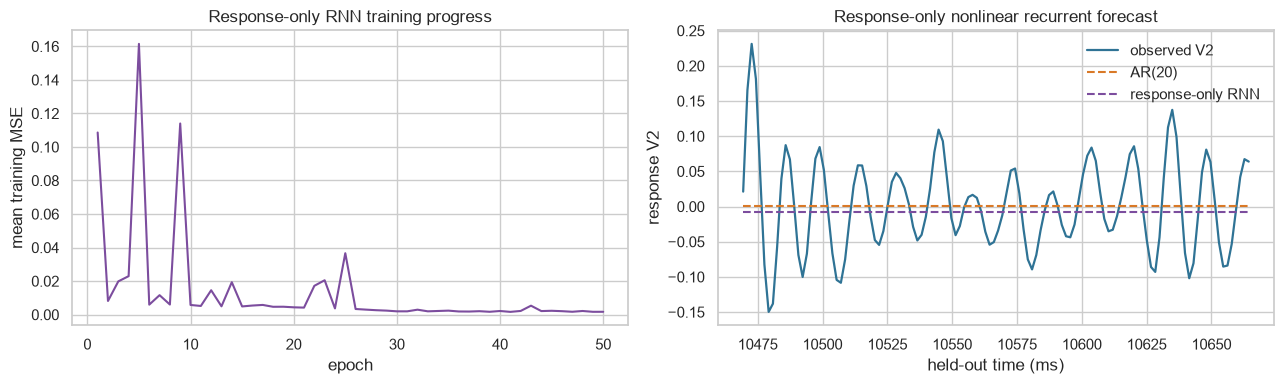

Response-only RNN recursive multi-step held-out RMSE: 0.05514


In [9]:
response_rnn_prediction = recursive_stateful_forecast(
    model=response_rnn_model,
    input_signal=None,
    observed_output=y_test,
    warmup=ORDER,
    input_mean=None,
    input_std=None,
    output_mean=y_mean,
    output_std=y_std,
)
response_rnn_rmse = rmse(
    actual=y_test,
    predicted=response_rnn_prediction,
    warmup=ORDER,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(
    np.arange(1, EPOCHS + 1),
    response_rnn_training_losses,
    color="#7c4d9e",
)
axes[0].set(
    xlabel="epoch",
    ylabel="mean training MSE",
    title="Response-only RNN training progress",
)

axes[1].plot(
    zoom_time,
    y_test[zoom_window],
    color="#2f7395",
    linewidth=1.6,
    label="observed V2",
)
axes[1].plot(
    zoom_time,
    ar_prediction[zoom_window],
    color="#d97927",
    linestyle="--",
    label="AR(20)",
)
axes[1].plot(
    zoom_time,
    response_rnn_prediction[zoom_window],
    color="#7c4d9e",
    linestyle="--",
    label="response-only RNN",
)
axes[1].set(
    xlabel="held-out time (ms)",
    ylabel="response V2",
    title="Response-only nonlinear recurrent forecast",
)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

print(
    "Response-only RNN recursive multi-step held-out RMSE: "
    f"{response_rnn_rmse:.5f}"
)

## 6. Give the RNN the known forcing input

The response-only RNN above is the recurrent analogue of AR: it only sees prior `V2` values. It cannot react directly when the applied excitation `V1` changes.

We now add the known forcing signal. At time $t$, the RNN receives the two-value input $[u_t, y_{t-1}]$ together with its prior hidden state:

$$
\mathbf{h}_t = 	anh(W_h \mathbf{h}_{t-1} + W_y y_{t-1} + W_u u_t + b_h),
\qquad \widehat{y}_t = f(\mathbf{h}_t).
$$

This is an **input-aware RNN**: the nonlinear recurrent counterpart to ARX. It has the same causal information pattern as ARX—the known current forcing signal and response history—but represents that history with a learned nonlinear state rather than a fixed, linear list of lags. The same teacher-forced training and state-carrying recursive held-out protocol apply.

In [10]:
# The input-aware RNN uses [current V1, previous V2] at every time step.
# Standardize V1 using the training experiment only.
u_mean, u_std = float(u_train.mean()), float(u_train.std())
u_train_scaled = (u_train - u_mean) / u_std

input_rnn_inputs, input_rnn_targets = make_teacher_forced_sequence(
    input_signal=u_train_scaled,
    output_signal=y_train_scaled,
)

# Use the same hidden size, chronological training record, and training budget.
torch.manual_seed(RANDOM_SEED)
rnn_model = RecurrentPredictor(input_size=2, hidden_size=HIDDEN_SIZE).to(device)
rnn_training_losses = train_stateful_sequence_model(
    model=rnn_model,
    inputs=input_rnn_inputs,
    targets=input_rnn_targets,
    epochs=EPOCHS,
    chunk_size=CHUNK_SIZE,
)

for epoch in range(10, EPOCHS + 1, 10):
    print(
        f"Input-aware RNN epoch {epoch:>3}: "
        f"mean chunk MSE = {rnn_training_losses[epoch - 1]:.5f}"
    )

Input-aware RNN epoch  10: mean chunk MSE = 0.00014
Input-aware RNN epoch  20: mean chunk MSE = 0.00010
Input-aware RNN epoch  30: mean chunk MSE = 0.00006
Input-aware RNN epoch  40: mean chunk MSE = 0.00013
Input-aware RNN epoch  50: mean chunk MSE = 0.00008


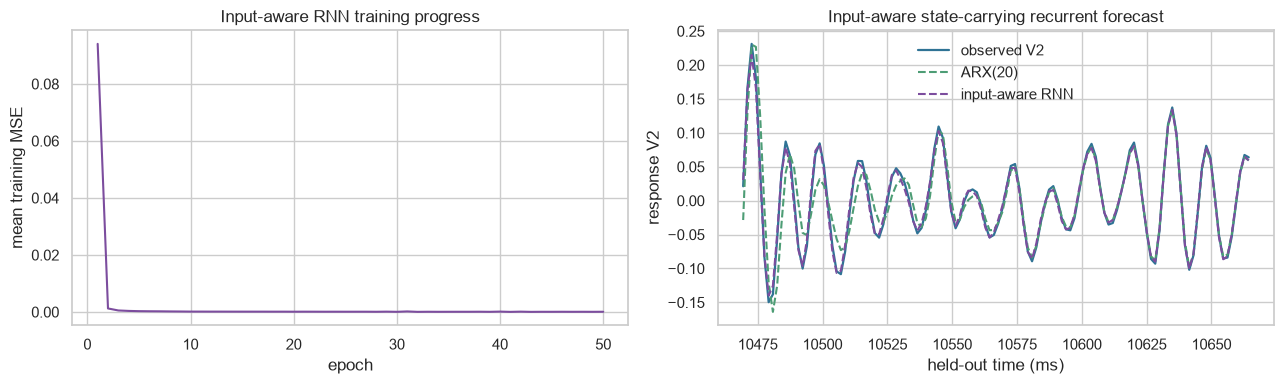

Input-aware RNN recursive multi-step held-out RMSE: 0.00379


In [11]:
rnn_prediction = recursive_stateful_forecast(
    model=rnn_model,
    input_signal=u_test,
    observed_output=y_test,
    warmup=ORDER,
    input_mean=u_mean,
    input_std=u_std,
    output_mean=y_mean,
    output_std=y_std,
)
rnn_rmse = rmse(actual=y_test, predicted=rnn_prediction, warmup=ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, EPOCHS + 1), rnn_training_losses, color="#7c4d9e")
axes[0].set(
    xlabel="epoch",
    ylabel="mean training MSE",
    title="Input-aware RNN training progress",
)

axes[1].plot(
    zoom_time,
    y_test[zoom_window],
    color="#2f7395",
    linewidth=1.6,
    label="observed V2",
)
axes[1].plot(
    zoom_time,
    arx_prediction[zoom_window],
    color="#4d9d75",
    linestyle="--",
    label="ARX(20)",
)
axes[1].plot(
    zoom_time,
    rnn_prediction[zoom_window],
    color="#7c4d9e",
    linestyle="--",
    label="input-aware RNN",
)
axes[1].set(
    xlabel="held-out time (ms)",
    ylabel="response V2",
    title="Input-aware state-carrying recurrent forecast",
)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

print(f"Input-aware RNN recursive multi-step held-out RMSE: {rnn_rmse:.5f}")

## 7. (Optional) Compare the input-aware RNN with an LSTM

An **LSTM (long short-term memory)** network is another recurrent architecture. Like the input-aware RNN above, it reads the same chronological input--response record and produces one next-response prediction at a time. Its gates control what information is stored, forgotten, and exposed through a separate cell state.

To isolate the architectural change, the comparison below keeps the 20-response warmup, 16 hidden values, optimizer, learning rate, epochs, truncated-backpropagation chunk length, and recursive held-out protocol fixed. The LSTM has more learned values because its gates add parameters, so this is a controlled illustration—not a claim of equal model capacity or a guarantee that an LSTM will always win.

In [12]:
class LSTMPredictor(torch.nn.Module):
    """Process an input--response sequence with an LSTM.

    Args:
        hidden_size: Number of values in the hidden and cell states.
    """

    def __init__(self, *, hidden_size: int) -> None:
        super().__init__()
        self.lstm = torch.nn.LSTM(
            input_size=2,  # [known input, previous response]
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.readout = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, hidden_size),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_size, 1),
        )

    def forward(
        self,
        sequence: torch.Tensor,
        hidden_state: tuple[torch.Tensor, torch.Tensor] | None = None,
    ) -> tuple[torch.Tensor, tuple[torch.Tensor, torch.Tensor]]:
        """Predict responses and return the hidden and cell states for the next step."""
        hidden_values, next_hidden_state = self.lstm(sequence, hidden_state)
        predictions = self.readout(hidden_values).squeeze(-1)
        return predictions, next_hidden_state

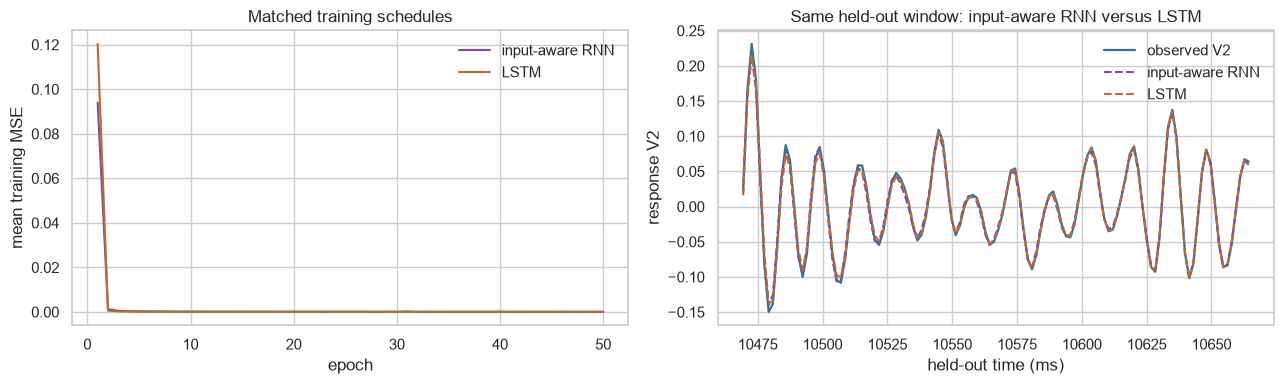

,model,information available,recursive multi-step held-out RMSE
0,AR(20),past response only,0.05429
1,ARX(20),past response + known forcing input,0.00694
2,response-only RNN,prior response + carried nonlinear state,0.05514
3,input-aware RNN,known forcing input + prior response + carried nonlinear state,0.00379
4,small LSTM,"same inputs + carried, gated hidden and cell states",0.00188


In [13]:
# Use the same random seed, chronological data, and truncated-BPTT chunks as the input-aware RNN.
torch.manual_seed(RANDOM_SEED)
lstm_model = LSTMPredictor(hidden_size=HIDDEN_SIZE).to(device)
lstm_training_losses = train_stateful_sequence_model(
    model=lstm_model,
    inputs=input_rnn_inputs,
    targets=input_rnn_targets,
    epochs=EPOCHS,
    chunk_size=CHUNK_SIZE,
)

lstm_prediction = recursive_stateful_forecast(
    model=lstm_model,
    input_signal=u_test,
    observed_output=y_test,
    warmup=ORDER,
    input_mean=u_mean,
    input_std=u_std,
    output_mean=y_mean,
    output_std=y_std,
)
lstm_rmse = rmse(actual=y_test, predicted=lstm_prediction, warmup=ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, EPOCHS + 1), rnn_training_losses, color="#7c4d9e", label="input-aware RNN")
axes[0].plot(np.arange(1, EPOCHS + 1), lstm_training_losses, color="#bd6b30", label="LSTM")
axes[0].set(xlabel="epoch", ylabel="mean training MSE", title="Matched training schedules")
axes[0].legend(frameon=False)

axes[1].plot(zoom_time, y_test[zoom_window], color="#2f7395", linewidth=1.6, label="observed V2")
axes[1].plot(zoom_time, rnn_prediction[zoom_window], color="#7c4d9e", linestyle="--", label="input-aware RNN")
axes[1].plot(zoom_time, lstm_prediction[zoom_window], color="#bd6b30", linestyle="--", label="LSTM")
axes[1].set(xlabel="held-out time (ms)", ylabel="response V2", title="Same held-out window: input-aware RNN versus LSTM")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "model": [
        f"AR({ORDER})",
        f"ARX({ORDER})",
        "response-only RNN",
        "input-aware RNN",
        "small LSTM",
    ],
    "information available": [
        "past response only",
        "past response + known forcing input",
        "prior response + carried nonlinear state",
        "known forcing input + prior response + carried nonlinear state",
        "same inputs + carried, gated hidden and cell states",
    ],
    "recursive multi-step held-out RMSE": [
        ar_rmse,
        arx_rmse,
        response_rnn_rmse,
        rnn_rmse,
        lstm_rmse,
    ],
})
display(comparison.style.format({"recursive multi-step held-out RMSE": "{:.5f}"}))

## 8. What this comparison does—and does not—show

- Adding `V1` helps because it is a known causal input that drives the system; neither AR nor the response-only RNN can react to it directly.
- The response-only RNN changes the representation of response history—from explicit linear lags to a learned nonlinear state—but it does not add new measured information.
- The input-aware RNN can learn nonlinear effects while using the known forcing signal, which is useful for this Duffing-like system.
- The LSTM adds gates that can preserve useful information, but it does **not** guarantee lower held-out error; its result here depends on this data and training configuration. Both input-aware recurrent models carry state forward after the same 20-response warmup. The 256-step training chunk limits gradient propagation, not how long state can persist during inference.
- The fair comparison is always on future or held-out experiments, with only information available at the forecasting time.
- A different recurrent architecture, training horizon, or input representation could also improve this task.

<p style="margin-top: 1.5rem;"><a href="index.html">← Return to Sequential models</a></p>